# ENGE707 Assessment 3 – Facial Feature Classification (Cat/Dog)

End-to-end deep learning pipeline for the 8-class Kaggle challenge
(CatEye, CatFace, CatMouth, CatNose, DogEye, DogFace, DogMouth, DogNose).

**How to run**
1. On Kaggle: attach the competition data, set *Accelerator → GPU* and *Internet → On*, then *Run All*.
2. Locally: put the unzipped competition data in a folder called `data/` next to this notebook, then run all cells.

The notebook finds the data automatically, so no paths need editing.
All figures, tables, model weights and `submission.csv` are saved to the output folder
(`/kaggle/working` on Kaggle, `outputs/` locally).

**Sections**
- Task 1 – Dataset exploration
- Task 2 – Preprocessing and data pipeline
- Task 3 – Model
- Task 4 – Training and over/underfitting monitoring
- Task 5 – Evaluation and Kaggle submission
- Task 6 – Error analysis and comparison experiments

In [1]:
!pip install -q -U kaggle
import os
TOKEN = "Paste token here"
os.environ["KAGGLE_API_TOKEN"] = TOKEN
os.makedirs(os.path.expanduser("~/.kaggle"), exist_ok=True)
open(os.path.expanduser("~/.kaggle/access_token"), "w").write(TOKEN)

!kaggle competitions download -c enge-707-2026-s-2-cat-and-dog-facial-feature-classification-ch
!mkdir -p data && unzip -q enge-707-*.zip -d data && ls data

100% 966M/966M [00:09<00:00, 107MB/s]

sample_submission.csv  test  train  train_labels.csv


## 0. Setup and configuration

In [4]:
import os, glob, random, hashlib, time, copy, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import torchvision
from torchvision import transforms, models

from sklearn.model_selection import train_test_split
from sklearn.metrics import (classification_report, confusion_matrix,
                             accuracy_score, precision_recall_fscore_support)

warnings.filterwarnings("ignore", category=UserWarning)
sns.set_theme(style="whitegrid")

# ---------------- Configuration (all key settings in one place) ----------------
SEED          = 42          # fixed seed so results can be reproduced
IMG_SIZE      = 224         # input size expected by ImageNet-pretrained CNNs
BATCH_SIZE    = 64
NUM_WORKERS   = os.cpu_count() or 2   # parallel image loading
VAL_FRACTION  = 0.20        # 80/20 stratified train/validation split

ARCH          = "resnet50"  # options: "resnet50", "efficientnet_b0", "resnet18"
DROPOUT       = 0.3         # dropout before the final classification layer
WARMUP_EPOCHS = 1           # stage 1: train only the new head (backbone frozen)
HEAD_LR       = 1e-3        # learning rate for stage 1
MAX_EPOCHS    = 6           # stage 2 upper limit (early stopping usually ends sooner)
FINETUNE_LR   = 1e-4        # learning rate for stage 2 (whole network)
WEIGHT_DECAY  = 1e-4        # L2-style regularisation (AdamW)
PATIENCE      = 2           # early stopping patience (epochs without val-loss improvement)
USE_TTA       = False       # test-time augmentation (horizontal flip) at prediction time
RUN_COMPARISONS = False     # Task 6: train extra model variants for comparison

def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
set_seed()

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
OUT_DIR = "/content/outputs" if os.path.isdir("/content") else ("/kaggle/working" if os.path.isdir("/kaggle/working") else "outputs")
os.makedirs(OUT_DIR, exist_ok=True)

print("Device:", DEVICE, "|", torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "CPU only")
print("PyTorch", torch.__version__, "| torchvision", torchvision.__version__)
print("Outputs saved to:", OUT_DIR)

Device: cuda | Tesla T4
PyTorch 2.11.0+cu130 | torchvision 0.26.0+cu130
Outputs saved to: /content/outputs


## Task 1 – Dataset exploration and understanding

### 1.1 Locate the data
The cell below searches the input folder for images and CSV files and works out:
- **training labels**, either from one-folder-per-class (`train/CatEye/...`) or from a labels CSV,
- **test images** (everything not labelled), matched to the IDs in the sample submission.

In [5]:
IMG_EXT = (".jpg", ".jpeg", ".png", ".bmp", ".webp", ".tif", ".tiff")
# Local / Colab: a "data" folder next to the notebook. Kaggle: the attached competition input.
DATA_ROOT = next((d for d in ["data", "/content/data"] if os.path.isdir(d)), "/kaggle/input")
EXPECTED_CLASSES = ["CatEye", "CatFace", "CatMouth", "CatNose",
                    "DogEye", "DogFace", "DogMouth", "DogNose"]

def norm(s):
    """Lower-case and strip non-alphanumerics so 'Cat_Eye', 'cateye', 'Cat Eye' all match."""
    return "".join(ch for ch in str(s).lower() if ch.isalnum())
BASE_KEYS = {norm(c) for c in EXPECTED_CLASSES}
def canon(s):
    """Map a class name to a canonical key, accepting singular/plural ('CatEye' or 'CatEyes')."""
    n = norm(s)
    if n not in BASE_KEYS and n.endswith("s") and n[:-1] in BASE_KEYS:
        n = n[:-1]
    return n if n in BASE_KEYS else None

all_images = sorted(p for p in glob.glob(os.path.join(DATA_ROOT, "**", "*"), recursive=True)
                    if p.lower().endswith(IMG_EXT))
csv_files  = sorted(glob.glob(os.path.join(DATA_ROOT, "**", "*.csv"), recursive=True))
assert len(all_images) > 0, f"No images found under {DATA_ROOT}. Is the competition data attached?"

print(f"Found {len(all_images)} images and {len(csv_files)} CSV file(s) under {DATA_ROOT}")
for c in csv_files:
    print("  CSV:", os.path.relpath(c, DATA_ROOT), "| columns:", list(pd.read_csv(c, nrows=1).columns))

def in_test_folder(p):
    parts = [norm(x) for x in os.path.relpath(p, DATA_ROOT).split(os.sep)[:-1]]
    return any(x.startswith("test") for x in parts)

# ---- Sample submission (defines the required output format) ----
sub_csvs = [c for c in csv_files if any(k in os.path.basename(c).lower() for k in ("sample", "submission"))]
sample_sub = pd.read_csv(sub_csvs[0], dtype=str) if sub_csvs else None
if sample_sub is not None:
    ID_COL, TARGET_COL = sample_sub.columns[0], sample_sub.columns[1]
    print(f"\nSample submission: {os.path.basename(sub_csvs[0])} | id column = '{ID_COL}', target column = '{TARGET_COL}'")
    display(sample_sub.head())
else:
    ID_COL, TARGET_COL = "id", "label"
    print("\nNo sample submission found - defaulting to columns 'id,label'.")

# ---- Strategy A: one folder per class ----
rows = []
for p in all_images:
    if in_test_folder(p):
        continue
    parent = norm(os.path.basename(os.path.dirname(p)))
    if canon(parent):
        rows.append((p, os.path.basename(os.path.dirname(p))))   # keep the dataset's own spelling
train_df = pd.DataFrame(rows, columns=["path", "label"])
label_source = "class folders"

# ---- Strategy B: labels CSV ----
if len(train_df) == 0:
    cand = [p for p in all_images if not in_test_folder(p)] or all_images
    by_name = {os.path.basename(p): p for p in cand}
    by_stem = {os.path.splitext(os.path.basename(p))[0]: p for p in cand}
    by_unpad = {(k.lstrip("0") or "0"): v for k, v in by_stem.items()}
    def lookup(v):
        b = os.path.basename(str(v))
        return (by_name.get(b) or by_stem.get(os.path.splitext(b)[0]) or by_stem.get(b)
                or by_unpad.get(os.path.splitext(b)[0].lstrip("0") or "0"))
    for c in csv_files:
        if c in sub_csvs:
            continue
        df = pd.read_csv(c, dtype=str)
        label_col = next((col for col in df.columns
                          if df[col].astype(str).map(canon).notna().mean() > 0.9), None)
        if label_col is None:
            continue
        for col in df.columns:
            if col == label_col:
                continue
            paths = df[col].map(lookup)
            if paths.notna().mean() > 0.9:
                train_df = pd.DataFrame({"path": paths,
                                         "label": df[label_col].astype(str).str.strip()}).dropna()
                label_source = f"{os.path.basename(c)} (id column '{col}', label column '{label_col}')"
                break
        if len(train_df):
            break

assert len(train_df) > 0, "Could not work out the training labels - check the folder layout printed above."
train_df = train_df.reset_index(drop=True)

# ---- Test images: everything that is not a labelled training image ----
labelled = set(train_df["path"])
test_pool = [p for p in all_images if p not in labelled]
if sample_sub is not None:
    t_name = {os.path.basename(p): p for p in test_pool}
    t_stem = {os.path.splitext(os.path.basename(p))[0]: p for p in test_pool}
    t_unpad = {(k.lstrip("0") or "0"): v for k, v in t_stem.items()}   # '1.jpg' vs id '00001'
    def find_test(v):
        b = os.path.basename(str(v))
        return (t_name.get(b) or t_stem.get(os.path.splitext(b)[0]) or t_stem.get(b)
                or t_unpad.get(os.path.splitext(b)[0].lstrip("0") or "0"))
    test_df = pd.DataFrame({ID_COL: sample_sub[ID_COL]})
    test_df["path"] = sample_sub[ID_COL].map(find_test)
    n_missing = test_df["path"].isna().sum()
    if n_missing:
        print(f"WARNING: {n_missing} submission IDs have no matching test image, e.g.",
              test_df.loc[test_df.path.isna(), ID_COL].head(3).tolist())
else:
    test_df = pd.DataFrame({ID_COL: [os.path.basename(p) for p in test_pool], "path": test_pool})

CLASSES = sorted(train_df["label"].unique())
CANON_TO_CLASS = {canon(c): c for c in CLASSES}
CLASS_TO_IDX = {c: i for i, c in enumerate(CLASSES)}
NUM_CLASSES = len(CLASSES)

print(f"\nTraining labels taken from: {label_source}")
print(f"Labelled training images: {len(train_df)} | Test images: {test_df['path'].notna().sum()}")
print("Classes:", CLASSES)

# Names written to submission.csv must match the official spelling exactly.
# Default: the spelling used in the training data. If the sample submission contains
# class names with a different spelling (e.g. 'CatEyes' vs 'CatEye'), use that instead.
OUTPUT_NAME = {c: c for c in CLASSES}
if sample_sub is not None and not pd.api.types.is_numeric_dtype(sample_sub[TARGET_COL]):
    for v in sample_sub[TARGET_COL].dropna().astype(str).str.strip().unique():
        k = canon(v)
        if k in CANON_TO_CLASS and OUTPUT_NAME[CANON_TO_CLASS[k]] != v:
            OUTPUT_NAME[CANON_TO_CLASS[k]] = v
print("Labels that will be written to submission.csv:", sorted(OUTPUT_NAME.values()))
if NUM_CLASSES != 8:
    print("WARNING: expected 8 classes, found", NUM_CLASSES)

Found 93103 images and 2 CSV file(s) under data
  CSV: sample_submission.csv | columns: ['image_id', 'class']
  CSV: train_labels.csv | columns: ['image_id', 'class']

Sample submission: sample_submission.csv | id column = 'image_id', target column = 'class'


,image_id,class
0,1,DogEye
1,2,CatNose
2,3,CatNose
3,4,DogFace
4,5,DogMouth



Training labels taken from: train_labels.csv (id column 'image_id', label column 'class')
Labelled training images: 63660 | Test images: 29443
Classes: ['CatEye', 'CatFace', 'CatMouth', 'CatNose', 'DogEye', 'DogFace', 'DogMouth', 'DogNose']
Labels that will be written to submission.csv: ['CatEye', 'CatFace', 'CatMouth', 'CatNose', 'DogEye', 'DogFace', 'DogMouth', 'DogNose']


### 1.2 Class distribution (balance check)

,images,percent
label,,
CatEye,13884,21.81
CatFace,6942,10.90
CatMouth,6942,10.90
CatNose,6942,10.90
DogEye,11580,18.19
DogFace,5790,9.10
DogMouth,5790,9.10
DogNose,5790,9.10


Largest/smallest class ratio: 2.40


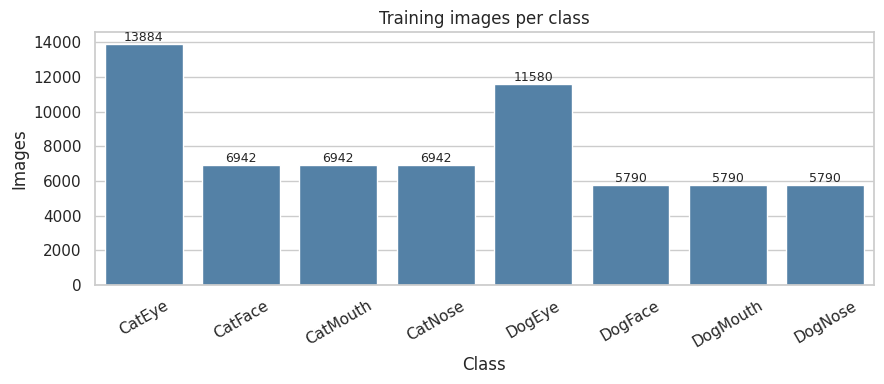

In [6]:
counts = train_df["label"].value_counts().reindex(CLASSES)
dist = pd.DataFrame({"images": counts, "percent": (100 * counts / counts.sum()).round(2)})
display(dist)
print(f"Largest/smallest class ratio: {counts.max() / counts.min():.2f}")
dist.to_csv(f"{OUT_DIR}/class_distribution.csv")

fig, ax = plt.subplots(figsize=(9, 4))
sns.barplot(x=counts.index, y=counts.values, ax=ax, color="steelblue")
for i, v in enumerate(counts.values):
    ax.text(i, v, str(v), ha="center", va="bottom", fontsize=9)
ax.set_title("Training images per class"); ax.set_xlabel("Class"); ax.set_ylabel("Images")
plt.xticks(rotation=30); plt.tight_layout()
plt.savefig(f"{OUT_DIR}/fig_class_distribution.png", dpi=150); plt.show()

### 1.3 Sample images from each class

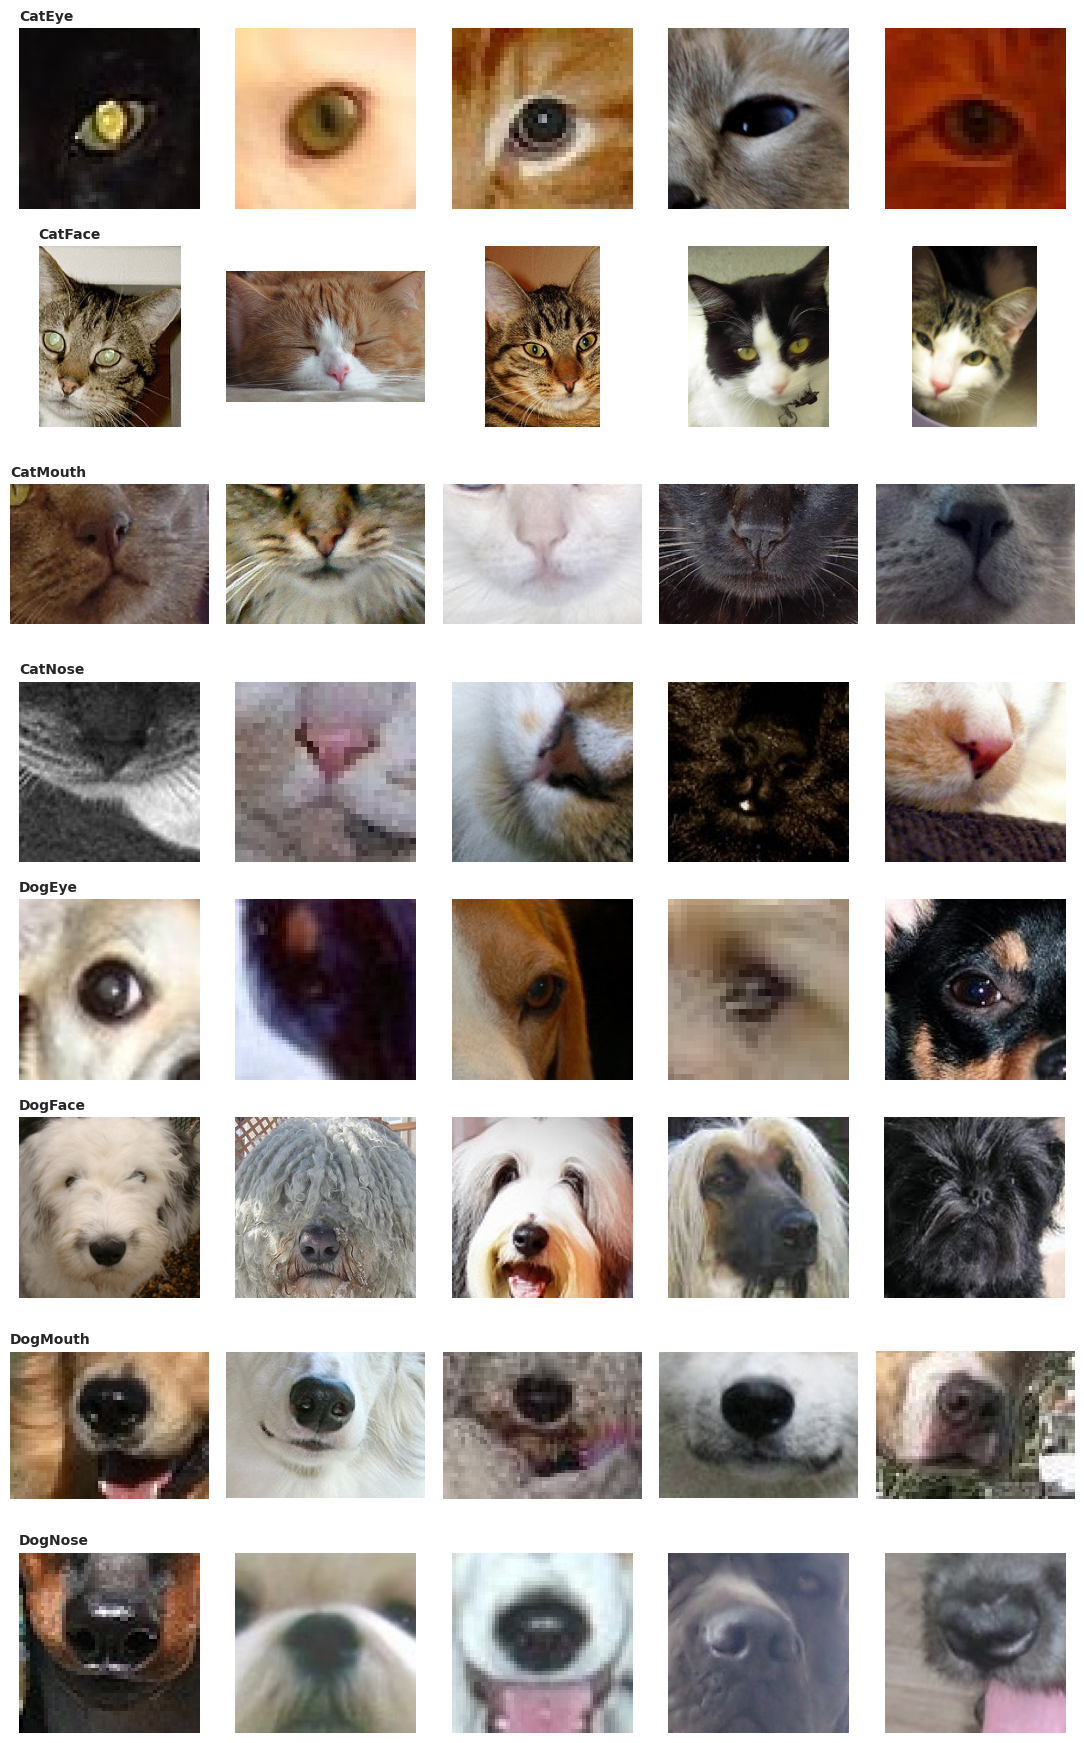

In [7]:
N_PER_CLASS = 5
fig, axes = plt.subplots(NUM_CLASSES, N_PER_CLASS, figsize=(2.2 * N_PER_CLASS, 2.2 * NUM_CLASSES))
for r, cls in enumerate(CLASSES):
    sample = train_df[train_df.label == cls].sample(min(N_PER_CLASS, (train_df.label == cls).sum()), random_state=SEED)
    for c in range(N_PER_CLASS):
        ax = axes[r, c]; ax.axis("off")
        if c < len(sample):
            try:
                ax.imshow(Image.open(sample.iloc[c].path).convert("RGB"))
            except Exception:
                ax.text(0.5, 0.5, "unreadable", ha="center")
        if c == 0:
            ax.set_title(cls, loc="left", fontsize=10, fontweight="bold")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/fig_samples_per_class.png", dpi=150); plt.show()

### 1.4 Data quality checks
For every image (train and test) this records the size, colour mode, whether the file opens
(corruption), an MD5 hash of the file (exact duplicates) and a sharpness score
(variance of the Laplacian; low values indicate blur).

Inspected 93103 images in 126s

Corrupt files: 0

Colour modes:
 split  mode
test   RGB     29443
train  RGB     63660

Image size summary (pixels):


width                                                 height         \
         count   mean    std  min   25%   50%    75%     max    count   mean   
split                                                                          
test   29443.0  113.5  100.7  8.0  53.0  82.0  140.0  1832.0  29443.0  109.7   
train  63660.0  113.1   98.5  4.0  54.0  84.0  138.0  2219.0  63660.0  109.7   

                                              
         std  min   25%   50%    75%     max  
split                                         
test   103.7  9.0  50.0  80.0  128.0  1978.0  
train  101.9  4.0  50.0  80.0  130.0  2219.0

Distinct sizes in train: 7861


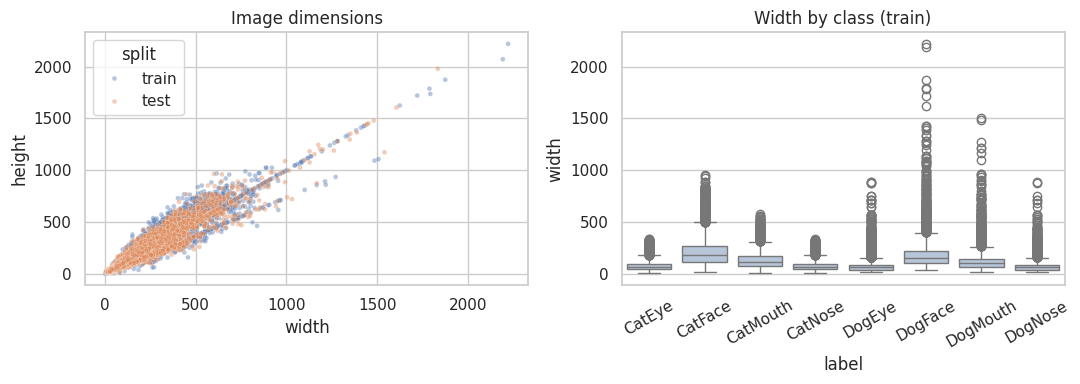

In [8]:
def laplacian_var(img):
    """Sharpness score: variance of a 3x3 Laplacian filter on a 128x128 greyscale copy."""
    g = np.asarray(img.convert("L").resize((128, 128)), dtype=np.float32)
    lap = (-4 * g[1:-1, 1:-1] + g[:-2, 1:-1] + g[2:, 1:-1] + g[1:-1, :-2] + g[1:-1, 2:])
    return float(lap.var())

def inspect(path):
    rec = {"path": path, "width": np.nan, "height": np.nan, "mode": None,
           "corrupt": False, "md5": None, "sharpness": np.nan}
    try:
        with open(path, "rb") as f:
            rec["md5"] = hashlib.md5(f.read()).hexdigest()
        with Image.open(path) as im:
            im.verify()                      # detects truncated/corrupt files
        with Image.open(path) as im:
            rec["width"], rec["height"], rec["mode"] = im.size[0], im.size[1], im.mode
            rec["sharpness"] = laplacian_var(im)
    except Exception:
        rec["corrupt"] = True
    return rec

t0 = time.time()
from concurrent.futures import ThreadPoolExecutor
with ThreadPoolExecutor(max_workers=8) as pool:  # inspect images in parallel (~93k files)
    q_train = pd.DataFrame(list(pool.map(inspect, train_df.path))) \
                .assign(split="train", label=train_df.label.values)
    q_test  = pd.DataFrame(list(pool.map(inspect, test_df.path.dropna()))) \
                .assign(split="test", label=None)
quality = pd.concat([q_train, q_test], ignore_index=True)
print(f"Inspected {len(quality)} images in {time.time() - t0:.0f}s")

print("\nCorrupt files:", quality.corrupt.sum())
print("\nColour modes:\n", quality.groupby(["split", "mode"]).size().to_string())
print("\nImage size summary (pixels):")
display(quality.groupby("split")[["width", "height"]].describe().round(1))
print("Distinct sizes in train:", q_train.groupby(["width", "height"]).ngroups)
quality.to_csv(f"{OUT_DIR}/image_quality_report.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.scatterplot(data=quality, x="width", y="height", hue="split", alpha=0.4, s=12, ax=axes[0])
axes[0].set_title("Image dimensions")
sns.boxplot(data=q_train, x="label", y="width", order=CLASSES, ax=axes[1], color="lightsteelblue")
axes[1].set_title("Width by class (train)"); axes[1].tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/fig_image_sizes.png", dpi=150); plt.show()

Duplicate files within train: 30 images in 15 groups
  ...of which have conflicting labels: 0 groups
Test files identical to a training file: 0 (reported only; test labels are never used)


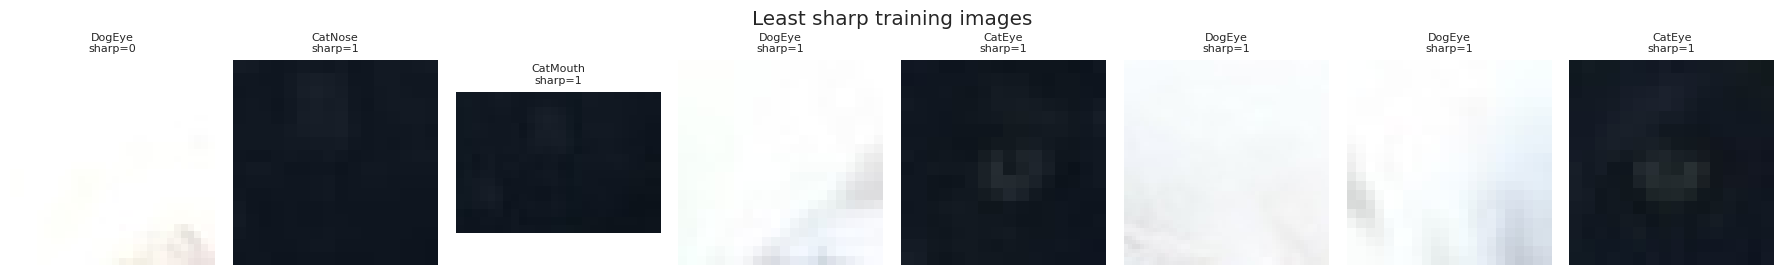

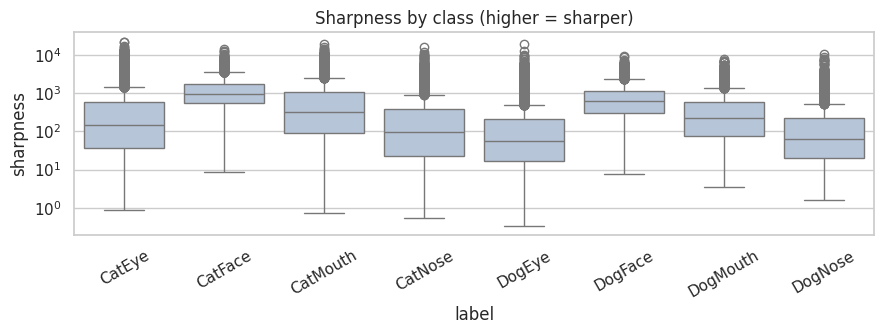

In [9]:
# ---- Exact duplicates (identical file bytes) ----
tr = q_train.dropna(subset=["md5"])
dup_groups = tr.groupby("md5").filter(lambda g: len(g) > 1)
conflicting = dup_groups.groupby("md5").filter(lambda g: g.label.nunique() > 1)
n_overlap = len(set(tr.md5) & set(q_test.md5.dropna()))
print(f"Duplicate files within train: {len(dup_groups)} images in {dup_groups.md5.nunique()} groups")
print(f"  ...of which have conflicting labels: {conflicting.md5.nunique()} groups")
print(f"Test files identical to a training file: {n_overlap} (reported only; test labels are never used)")

# ---- Blur: show the least sharp training images ----
blurry = q_train.dropna(subset=["sharpness"]).nsmallest(8, "sharpness")
fig, axes = plt.subplots(1, 8, figsize=(18, 2.8))
for ax, (_, r) in zip(axes, blurry.iterrows()):
    ax.imshow(Image.open(r.path).convert("RGB")); ax.axis("off")
    ax.set_title(f"{r.label}\nsharp={r.sharpness:.0f}", fontsize=8)
plt.suptitle("Least sharp training images"); plt.tight_layout()
plt.savefig(f"{OUT_DIR}/fig_blurriest.png", dpi=150); plt.show()

fig, ax = plt.subplots(figsize=(9, 3.5))
sns.boxplot(data=q_train, x="label", y="sharpness", order=CLASSES, ax=ax, color="lightsteelblue")
ax.set_yscale("log"); ax.set_title("Sharpness by class (higher = sharper)"); ax.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/fig_sharpness_by_class.png", dpi=150); plt.show()

## Task 2 – Preprocessing and data pipeline

### 2.1 Cleaning and stratified split
- Corrupt files are removed.
- Exact duplicates are reduced to one copy, and duplicate groups with conflicting labels are dropped,
  so the same image cannot appear in both training and validation (leakage).
- Labels are encoded as integers 0–7 (alphabetical class order).
- An 80/20 split **stratified by class** keeps the class proportions the same in both sets.

In [10]:
clean = train_df.merge(q_train[["path", "corrupt", "md5"]], on="path")
n0 = len(clean)
clean = clean[~clean.corrupt]
bad_md5 = set(conflicting.md5)
clean = clean[~clean.md5.isin(bad_md5)].drop_duplicates("md5", keep="first")
clean["y"] = clean.label.map(CLASS_TO_IDX)
print(f"Images before cleaning: {n0} | after: {len(clean)} | removed: {n0 - len(clean)}")

tr_df, va_df = train_test_split(clean, test_size=VAL_FRACTION, stratify=clean.y, random_state=SEED)
tr_df, va_df = tr_df.reset_index(drop=True), va_df.reset_index(drop=True)
assert not set(tr_df.md5) & set(va_df.md5), "Leakage: identical image in train and validation"

split_table = pd.DataFrame({"train": tr_df.label.value_counts(), "val": va_df.label.value_counts()}).reindex(CLASSES)
split_table["val %"] = (100 * split_table.val / (split_table.train + split_table.val)).round(1)
display(split_table)
pd.concat([tr_df.assign(split="train"), va_df.assign(split="val")])[["path", "label", "y", "split"]] \
  .to_csv(f"{OUT_DIR}/train_val_split.csv", index=False)
print("Label encoding:", CLASS_TO_IDX)

Images before cleaning: 63660 | after: 63645 | removed: 15


,train,val,val %
label,,,
CatEye,11102,2775,20.0
CatFace,5553,1389,20.0
CatMouth,5553,1388,20.0
CatNose,5553,1388,20.0
DogEye,9261,2315,20.0
DogFace,4630,1158,20.0
DogMouth,4632,1158,20.0
DogNose,4632,1158,20.0


Label encoding: {'CatEye': 0, 'CatFace': 1, 'CatMouth': 2, 'CatNose': 3, 'DogEye': 4, 'DogFace': 5, 'DogMouth': 6, 'DogNose': 7}


### 2.2 Transforms, datasets and data loaders
- **Train:** random resized crop (80–100% of the image) to 224×224, horizontal flip, ±10° rotation and colour jitter (augmentation).
- **Validation/test:** resize to 224×224 only, with no randomness, so evaluation is deterministic.
- **All splits:** convert to tensors and normalise with the ImageNet mean/std that the pretrained weights expect.

Batches - train: 796, val: 199, test: 461


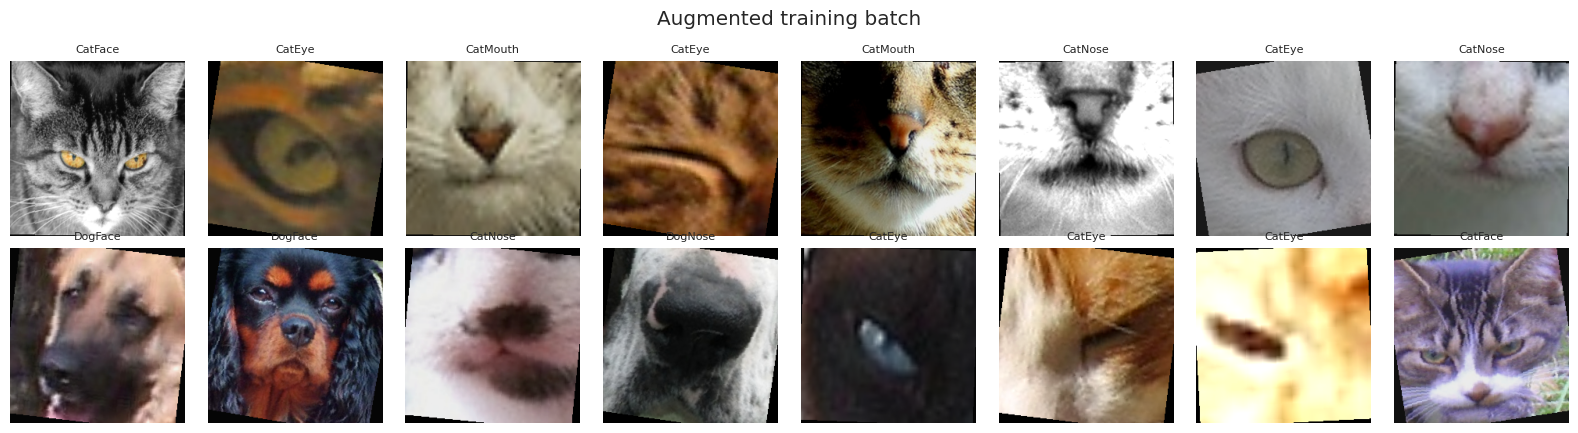

In [11]:
IMAGENET_MEAN, IMAGENET_STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

train_tf = transforms.Compose([
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.8, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])
eval_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

class ImageDataset(Dataset):
    def __init__(self, paths, labels=None, transform=None):
        self.paths, self.labels, self.transform = list(paths), labels, transform
    def __len__(self):
        return len(self.paths)
    def __getitem__(self, i):
        img = Image.open(self.paths[i]).convert("RGB")   # handles greyscale / RGBA images
        x = self.transform(img)
        y = -1 if self.labels is None else int(self.labels[i])
        return x, y

def make_loader(df, transform, shuffle, labels=True):
    ds = ImageDataset(df.path, df.y.values if labels else None, transform)
    g = torch.Generator(); g.manual_seed(SEED)
    return DataLoader(ds, batch_size=BATCH_SIZE, shuffle=shuffle, num_workers=NUM_WORKERS,
                      pin_memory=DEVICE.type == "cuda", generator=g)

train_loader = make_loader(tr_df, train_tf, shuffle=True)
val_loader   = make_loader(va_df, eval_tf, shuffle=False)
test_ready   = test_df.dropna(subset=["path"]).reset_index(drop=True)
test_loader  = make_loader(test_ready, eval_tf, shuffle=False, labels=False)
print(f"Batches - train: {len(train_loader)}, val: {len(val_loader)}, test: {len(test_loader)}")

# Show what the model actually sees after augmentation
xb, yb = next(iter(train_loader))
mean, std = torch.tensor(IMAGENET_MEAN).view(3, 1, 1), torch.tensor(IMAGENET_STD).view(3, 1, 1)
fig, axes = plt.subplots(2, 8, figsize=(16, 4.4))
for ax, x, y in zip(axes.flat, xb[:16], yb[:16]):
    ax.imshow((x * std + mean).clamp(0, 1).permute(1, 2, 0)); ax.axis("off"); ax.set_title(CLASSES[y], fontsize=8)
plt.suptitle("Augmented training batch"); plt.tight_layout()
plt.savefig(f"{OUT_DIR}/fig_augmented_batch.png", dpi=150); plt.show()

## Task 3 – Model

Transfer learning: an ImageNet-pretrained CNN with its final layer replaced by
`Dropout → Linear(features, 8)`. The network outputs 8 raw scores (logits);
softmax turns them into class probabilities, and `CrossEntropyLoss` applies
log-softmax internally during training.

In [12]:
def build_model(arch=ARCH, num_classes=NUM_CLASSES, dropout=DROPOUT):
    if arch == "resnet50":
        m = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V2)
        m.fc = nn.Sequential(nn.Dropout(dropout), nn.Linear(m.fc.in_features, num_classes)); head = m.fc
    elif arch == "resnet18":
        m = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
        m.fc = nn.Sequential(nn.Dropout(dropout), nn.Linear(m.fc.in_features, num_classes)); head = m.fc
    elif arch == "efficientnet_b0":
        m = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1)
        m.classifier = nn.Sequential(nn.Dropout(dropout), nn.Linear(m.classifier[1].in_features, num_classes))
        head = m.classifier
    else:
        raise ValueError(arch)
    return m.to(DEVICE), head

def set_backbone_trainable(model, head, trainable):
    for p in model.parameters():
        p.requires_grad = trainable
    for p in head.parameters():
        p.requires_grad = True

def count_params(model):
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return total, trainable

_m, _h = build_model()
print(_h)
print(f"{ARCH}: {count_params(_m)[0]:,} parameters | input 3x{IMG_SIZE}x{IMG_SIZE} | output {NUM_CLASSES} logits")
del _m, _h

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 152MB/s]


Sequential(
  (0): Dropout(p=0.3, inplace=False)
  (1): Linear(in_features=2048, out_features=8, bias=True)
)
resnet50: 23,524,424 parameters | input 3x224x224 | output 8 logits


## Task 4 – Training strategy and over/underfitting monitoring

Two-stage fine-tuning:
1. **Stage 1 (warm-up):** backbone frozen, only the new head trained (lr = `HEAD_LR`), so the random head
   doesn't push large gradients into the pretrained weights.
2. **Stage 2 (fine-tune):** all layers trained with a lower learning rate (`FINETUNE_LR`), AdamW weight decay,
   `ReduceLROnPlateau` (halve the LR when validation loss stalls) and **early stopping** on validation loss.
   The weights from the best validation-loss epoch are kept.

Mixed-precision (AMP) is used on GPU for speed.

In [14]:
def run_epoch(model, loader, criterion, optimizer=None, scaler=None):
    train = optimizer is not None
    model.train(train)
    tot_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(train):
        for x, y in loader:
            x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
            with torch.autocast(device_type=DEVICE.type, enabled=DEVICE.type == "cuda"):
                out = model(x); loss = criterion(out, y)
            if train:
                optimizer.zero_grad(set_to_none=True)
                scaler.scale(loss).backward(); scaler.step(optimizer); scaler.update()
            tot_loss += loss.item() * x.size(0)
            correct += (out.argmax(1) == y).sum().item(); n += x.size(0)
    return tot_loss / n, correct / n

def train_model(name, arch=ARCH, train_loader=train_loader, val_loader=val_loader,
                warmup_epochs=WARMUP_EPOCHS, max_epochs=MAX_EPOCHS, fine_tune=True,
                head_lr=HEAD_LR, finetune_lr=FINETUNE_LR, patience=PATIENCE, dropout=DROPOUT):
    set_seed()
    model, head = build_model(arch, dropout=dropout)
    criterion = nn.CrossEntropyLoss()
    scaler = torch.cuda.amp.GradScaler(enabled=DEVICE.type == "cuda")
    hist, best_loss, best_state, best_epoch, bad, epoch = [], float("inf"), None, 0, 0, 0

    stages = [("warmup", warmup_epochs, False, head_lr)]
    stages.append(("finetune", max_epochs, True, finetune_lr) if fine_tune
                  else ("head-only", max_epochs, False, head_lr))
    for stage, n_ep, unfreeze, lr in stages:
        set_backbone_trainable(model, head, unfreeze)
        opt = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad], lr=lr, weight_decay=WEIGHT_DECAY)
        sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode="min", factor=0.5, patience=1)
        print(f"[{name}] stage '{stage}': {count_params(model)[1]:,} trainable params, lr={lr}")
        for _ in range(n_ep):
            epoch += 1; t0 = time.time()
            tr_loss, tr_acc = run_epoch(model, train_loader, criterion, opt, scaler)
            va_loss, va_acc = run_epoch(model, val_loader, criterion)
            sched.step(va_loss)
            hist.append(dict(epoch=epoch, stage=stage, train_loss=tr_loss, train_acc=tr_acc,
                             val_loss=va_loss, val_acc=va_acc, lr=opt.param_groups[0]["lr"], secs=time.time() - t0))
            flag = ""
            if va_loss < best_loss - 1e-4:
                best_loss, best_epoch, bad = va_loss, epoch, 0
                best_state = copy.deepcopy(model.state_dict()); flag = "  *best*"
            elif stage != "warmup":
                bad += 1
            print(f"  ep {epoch:02d} | train loss {tr_loss:.4f} acc {tr_acc:.4f} | "
                  f"val loss {va_loss:.4f} acc {va_acc:.4f} | {hist[-1]['secs']:.0f}s{flag}")
            if stage != "warmup" and bad >= patience:
                print(f"  Early stopping: no val-loss improvement for {patience} epochs.")
                break
    model.load_state_dict(best_state)
    hist = pd.DataFrame(hist)
    print(f"[{name}] best epoch {best_epoch}: val loss {best_loss:.4f}, "
          f"val acc {hist.loc[hist.epoch == best_epoch, 'val_acc'].item():.4f}")
    return model, hist, best_epoch

def plot_history(hist, best_epoch, title, fname):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for ax, metric in zip(axes, ["loss", "acc"]):
        ax.plot(hist.epoch, hist[f"train_{metric}"], "o-", label="train")
        ax.plot(hist.epoch, hist[f"val_{metric}"], "s-", label="validation")
        ax.axvline(best_epoch, color="green", ls="--", lw=1, label=f"best epoch ({best_epoch})")
        if (hist.stage == "warmup").any() and (hist.stage != "warmup").any():
            ax.axvline(hist[hist.stage == "warmup"].epoch.max() + 0.5, color="grey", ls=":", lw=1, label="unfreeze")
        ax.set_xlabel("epoch"); ax.set_ylabel(metric); ax.set_title(f"{title} - {metric}"); ax.legend()
    plt.tight_layout(); plt.savefig(f"{OUT_DIR}/{fname}", dpi=150); plt.show()

[main] stage 'warmup': 16,392 trainable params, lr=0.001


/tmp/ipykernel_4772/2908951923.py:23: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=DEVICE.type == "cuda")


  ep 01 | train loss 0.8628 acc 0.7151 | val loss 0.6153 acc 0.7925 | 271s  *best*
[main] stage 'finetune': 23,524,424 trainable params, lr=0.0001
  ep 02 | train loss 0.1372 acc 0.9515 | val loss 0.0615 acc 0.9786 | 319s  *best*
  ep 03 | train loss 0.0550 acc 0.9798 | val loss 0.0463 acc 0.9826 | 315s  *best*
  ep 04 | train loss 0.0409 acc 0.9859 | val loss 0.0295 acc 0.9899 | 317s  *best*
  ep 05 | train loss 0.0343 acc 0.9880 | val loss 0.0425 acc 0.9857 | 315s
  ep 06 | train loss 0.0316 acc 0.9884 | val loss 0.0231 acc 0.9925 | 321s  *best*
  ep 07 | train loss 0.0283 acc 0.9895 | val loss 0.0306 acc 0.9891 | 322s
[main] best epoch 6: val loss 0.0231, val acc 0.9925


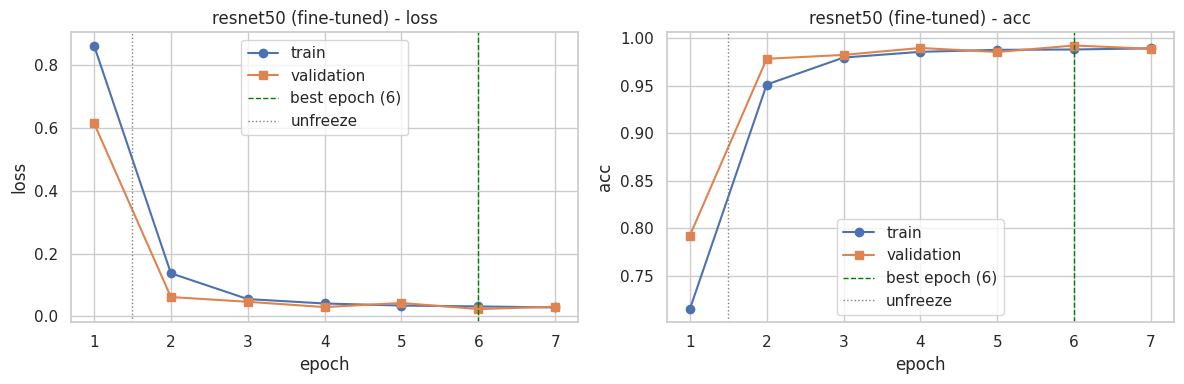

           best epoch final epoch
train_loss   0.031568    0.028251
val_loss     0.023146     0.03056
train_acc    0.988353    0.989532
val_acc      0.992537     0.98908
Train-val accuracy gap at best epoch: -0.0042
Total training time: 36.4 min


In [15]:
model, history, best_epoch = train_model("main", arch=ARCH)
history.to_csv(f"{OUT_DIR}/history_main.csv", index=False)
torch.save(model.state_dict(), f"{OUT_DIR}/best_model_{ARCH}.pth")
plot_history(history, best_epoch, f"{ARCH} (fine-tuned)", "fig_learning_curves.png")

last = history.iloc[-1]; best = history[history.epoch == best_epoch].iloc[0]
print(pd.DataFrame({"best epoch": best[["train_loss", "val_loss", "train_acc", "val_acc"]],
                    "final epoch": last[["train_loss", "val_loss", "train_acc", "val_acc"]]}).round(4))
print(f"Train-val accuracy gap at best epoch: {best.train_acc - best.val_acc:+.4f}")
print(f"Total training time: {history.secs.sum() / 60:.1f} min")

## Task 5 – Evaluation and Kaggle submission

### 5.1 Validation metrics

Validation accuracy: 0.9925 | loss: 0.0231 | macro precision 0.9923, recall 0.9925, F1 0.9924


,precision,recall,f1-score,support
CatEye,0.9953,0.9960,0.9957,2775.0000
CatFace,1.0000,0.9986,0.9993,1389.0000
CatMouth,0.9842,0.9870,0.9856,1388.0000
CatNose,0.9805,0.9777,0.9791,1388.0000
DogEye,0.9935,0.9905,0.9920,2315.0000
DogFace,0.9991,0.9983,0.9987,1158.0000
DogMouth,0.9940,0.9974,0.9957,1158.0000
DogNose,0.9914,0.9948,0.9931,1158.0000
accuracy,0.9925,0.9925,0.9925,0.9925
macro avg,0.9923,0.9925,0.9924,12729.0000


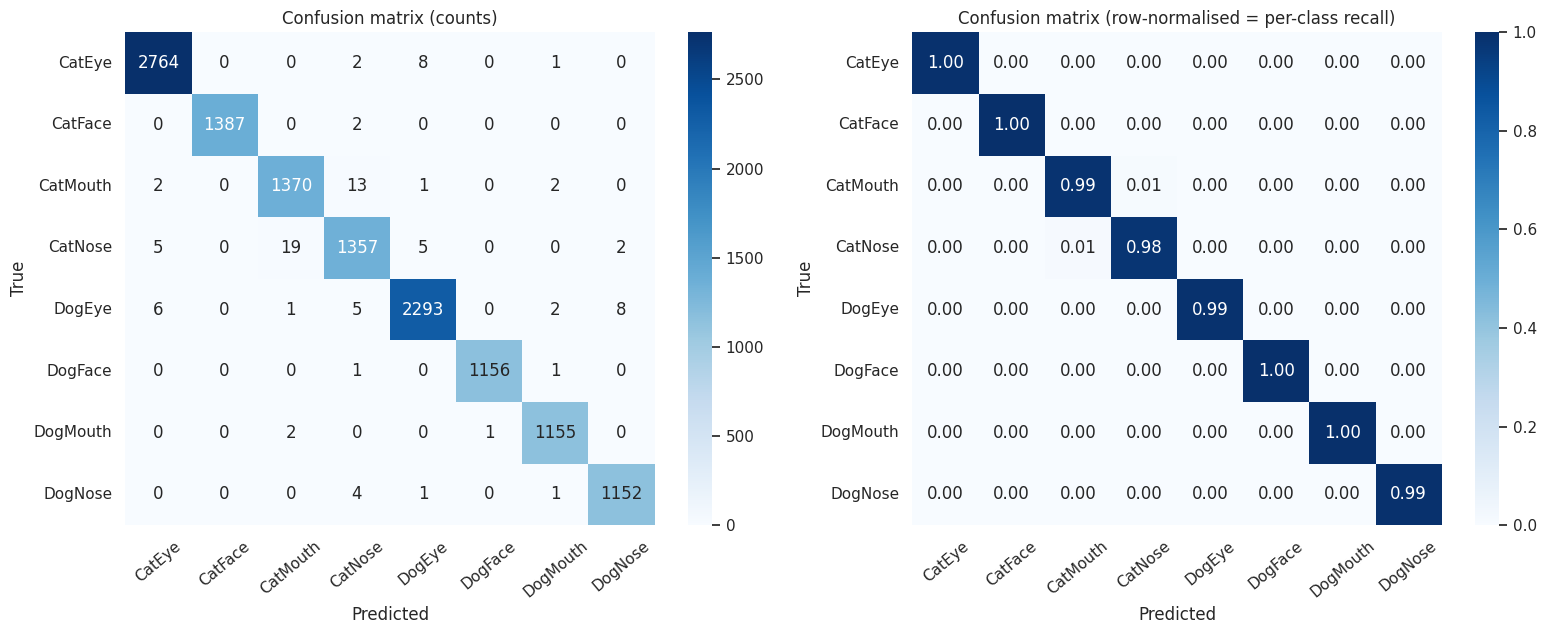

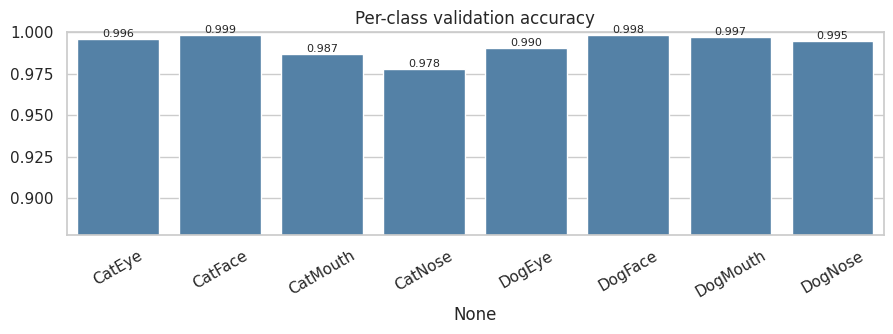

In [16]:
@torch.no_grad()
def predict(model, loader, tta=False):
    model.eval(); probs, ys = [], []
    for x, y in loader:
        x = x.to(DEVICE)
        with torch.autocast(device_type=DEVICE.type, enabled=DEVICE.type == "cuda"):
            logits = model(x).float()
            if tta:
                logits = (logits + model(torch.flip(x, dims=[3])).float()) / 2
        probs.append(torch.softmax(logits, 1).cpu()); ys.append(y)
    return torch.cat(probs).numpy(), torch.cat(ys).numpy()

val_probs, val_y = predict(model, val_loader, tta=USE_TTA)
val_pred = val_probs.argmax(1)
val_loss = nn.functional.nll_loss(torch.log(torch.tensor(val_probs) + 1e-12), torch.tensor(val_y)).item()
val_acc = accuracy_score(val_y, val_pred)
p, r, f1, _ = precision_recall_fscore_support(val_y, val_pred, average="macro")
print(f"Validation accuracy: {val_acc:.4f} | loss: {val_loss:.4f} | macro precision {p:.4f}, recall {r:.4f}, F1 {f1:.4f}")

report = pd.DataFrame(classification_report(val_y, val_pred, target_names=CLASSES, output_dict=True, digits=4)).T
display(report.round(4)); report.to_csv(f"{OUT_DIR}/classification_report.csv")

cm = confusion_matrix(val_y, val_pred, labels=range(NUM_CLASSES))
fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASSES, yticklabels=CLASSES, ax=axes[0])
axes[0].set_title("Confusion matrix (counts)")
sns.heatmap(cm / cm.sum(1, keepdims=True), annot=True, fmt=".2f", cmap="Blues",
            xticklabels=CLASSES, yticklabels=CLASSES, ax=axes[1], vmin=0, vmax=1)
axes[1].set_title("Confusion matrix (row-normalised = per-class recall)")
for ax in axes:
    ax.set_xlabel("Predicted"); ax.set_ylabel("True"); ax.tick_params(axis="x", rotation=40)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/fig_confusion_matrix.png", dpi=150); plt.show()

per_class_acc = pd.Series(cm.diagonal() / cm.sum(1), index=CLASSES)
fig, ax = plt.subplots(figsize=(9, 3.5))
sns.barplot(x=per_class_acc.index, y=per_class_acc.values, ax=ax, color="steelblue")
ax.set_ylim(max(0, per_class_acc.min() - 0.1), 1.0); ax.set_title("Per-class validation accuracy")
for i, v in enumerate(per_class_acc.values):
    ax.text(i, v, f"{v:.3f}", ha="center", va="bottom", fontsize=8)
plt.xticks(rotation=30); plt.tight_layout(); plt.savefig(f"{OUT_DIR}/fig_per_class_accuracy.png", dpi=150); plt.show()

### 5.2 Test predictions and submission file

In [17]:
test_probs, _ = predict(model, test_loader, tta=USE_TTA)
test_pred = test_probs.argmax(1)
ids = sample_sub[ID_COL] if sample_sub is not None else test_ready[ID_COL]
row_of = {v: i for i, v in enumerate(test_ready[ID_COL])}

# Work out which submission format the competition wants
prob_cols = [c for c in sample_sub.columns[1:] if canon(c) in CANON_TO_CLASS] if sample_sub is not None else []
if len(prob_cols) >= 2:
    # One probability column per class (used with log-loss style metrics)
    SUB_FORMAT = "probabilities"
    submission = pd.DataFrame({ID_COL: ids})
    rows = submission[ID_COL].map(row_of)
    assert rows.notna().all(), "Some test IDs have no prediction"
    for col in prob_cols:
        submission[col] = test_probs[rows.astype(int).values, CLASS_TO_IDX[CANON_TO_CLASS[canon(col)]]]
    submission = submission[list(sample_sub.columns)]
    pred_labels = pd.Series([CLASSES[i] for i in test_pred])
else:
    # One predicted label per image (used with accuracy / F1 metrics)
    SUB_FORMAT = "labels"
    numeric_target = sample_sub is not None and pd.api.types.is_numeric_dtype(sample_sub[TARGET_COL])
    pred_map = dict(zip(test_ready[ID_COL], test_pred if numeric_target else [OUTPUT_NAME[CLASSES[i]] for i in test_pred]))
    submission = pd.DataFrame({ID_COL: ids})
    submission[TARGET_COL] = submission[ID_COL].map(pred_map)
    assert submission[TARGET_COL].notna().all(), "Some test IDs have no prediction"
    if numeric_target:
        print("NOTE: sample submission uses numeric labels - writing class indices:", CLASS_TO_IDX)
    if sample_sub is not None:
        assert list(submission.columns) == list(sample_sub.columns[:2])
    pred_labels = submission[TARGET_COL]

if sample_sub is not None:
    assert len(submission) == len(sample_sub), "Row count differs from sample submission"
submission.to_csv(f"{OUT_DIR}/submission.csv", index=False)
print(f"Submission format: {SUB_FORMAT} | saved {OUT_DIR}/submission.csv with {len(submission)} rows")
display(submission.head())
print("\nPredicted class distribution (test):")
print(pd.Series(pred_labels).value_counts().to_string())

Submission format: labels | saved /content/outputs/submission.csv with 29443 rows


,image_id,class
0,1,DogEye
1,2,DogMouth
2,3,DogNose
3,4,DogFace
4,5,CatMouth



Predicted class distribution (test):
class
CatEye      6326
DogEye      5496
CatMouth    3218
CatFace     3102
CatNose     2982
DogMouth    2867
DogFace     2797
DogNose     2655


### 5.3 Validation vs Kaggle score
Upload `submission.csv` on the competition's **Submit Predictions** page, then type the public
leaderboard score below and re-run this cell. Screenshot the Submissions page and the Leaderboard for the report.

In [18]:
KAGGLE_PUBLIC_SCORE = 0.9732   # public leaderboard score (metric: accuracy)

comparison = pd.DataFrame({"metric": ["Validation accuracy", "Kaggle public accuracy"],
                           "value": [round(val_acc, 4), KAGGLE_PUBLIC_SCORE]})
display(comparison)
print(f"Difference (Kaggle - validation): {KAGGLE_PUBLIC_SCORE - val_acc:+.4f}")
comparison.to_csv(f"{OUT_DIR}/val_vs_kaggle.csv", index=False)

,metric,value
0,Validation accuracy,0.9925
1,Kaggle public accuracy,0.9732


Difference (Kaggle - validation): -0.0193


## Task 6 – Error analysis and comparison experiments

### 6.1 Which classes get confused?

In [19]:
pairs = [(CLASSES[i], CLASSES[j], cm[i, j]) for i in range(NUM_CLASSES) for j in range(NUM_CLASSES) if i != j and cm[i, j] > 0]
confused = pd.DataFrame(pairs, columns=["true", "predicted", "count"]).sort_values("count", ascending=False)
confused["% of true class"] = (100 * confused["count"] / confused["true"].map(dict(zip(CLASSES, cm.sum(1))))).round(2)
print(f"Total validation errors: {len(val_y) - (val_pred == val_y).sum()} of {len(val_y)}")
display(confused.head(10)); confused.to_csv(f"{OUT_DIR}/most_confused_pairs.csv", index=False)

# Split each class into species (Cat/Dog) and part (Eye/Face/Mouth/Nose)
species = lambda c: "Cat" if c.lower().startswith("cat") else "Dog"
part    = lambda c: c[3:]
t_cls, p_cls = [CLASSES[i] for i in val_y], [CLASSES[i] for i in val_pred]
err = [(t, p) for t, p in zip(t_cls, p_cls) if t != p]
err_types = pd.Series(["species only" if part(t) == part(p) else
                       ("part only" if species(t) == species(p) else "species and part") for t, p in err]).value_counts()
print("\nError types (species = cat vs dog, part = eye/face/mouth/nose):")
print(err_types.to_string() if len(err_types) else "no errors")
print(f"\nSpecies-level accuracy (cat vs dog): {np.mean([species(t) == species(p) for t, p in zip(t_cls, p_cls)]):.4f}")
print(f"Part-level accuracy (ignoring species): {np.mean([part(t) == part(p) for t, p in zip(t_cls, p_cls)]):.4f}")

Total validation errors: 95 of 12729


,true,predicted,count,% of true class
9,CatNose,CatMouth,19,1.37
5,CatMouth,CatNose,13,0.94
16,DogEye,DogNose,8,0.35
1,CatEye,DogEye,8,0.29
12,DogEye,CatEye,6,0.26
10,CatNose,DogEye,5,0.36
8,CatNose,CatEye,5,0.36
14,DogEye,CatNose,5,0.22
21,DogNose,CatNose,4,0.35
15,DogEye,DogMouth,2,0.09



Error types (species = cat vs dog, part = eye/face/mouth/nose):
part only           57
species only        24
species and part    14

Species-level accuracy (cat vs dog): 0.9970
Part-level accuracy (ignoring species): 0.9944


### 6.2 Misclassified validation images and prediction confidence

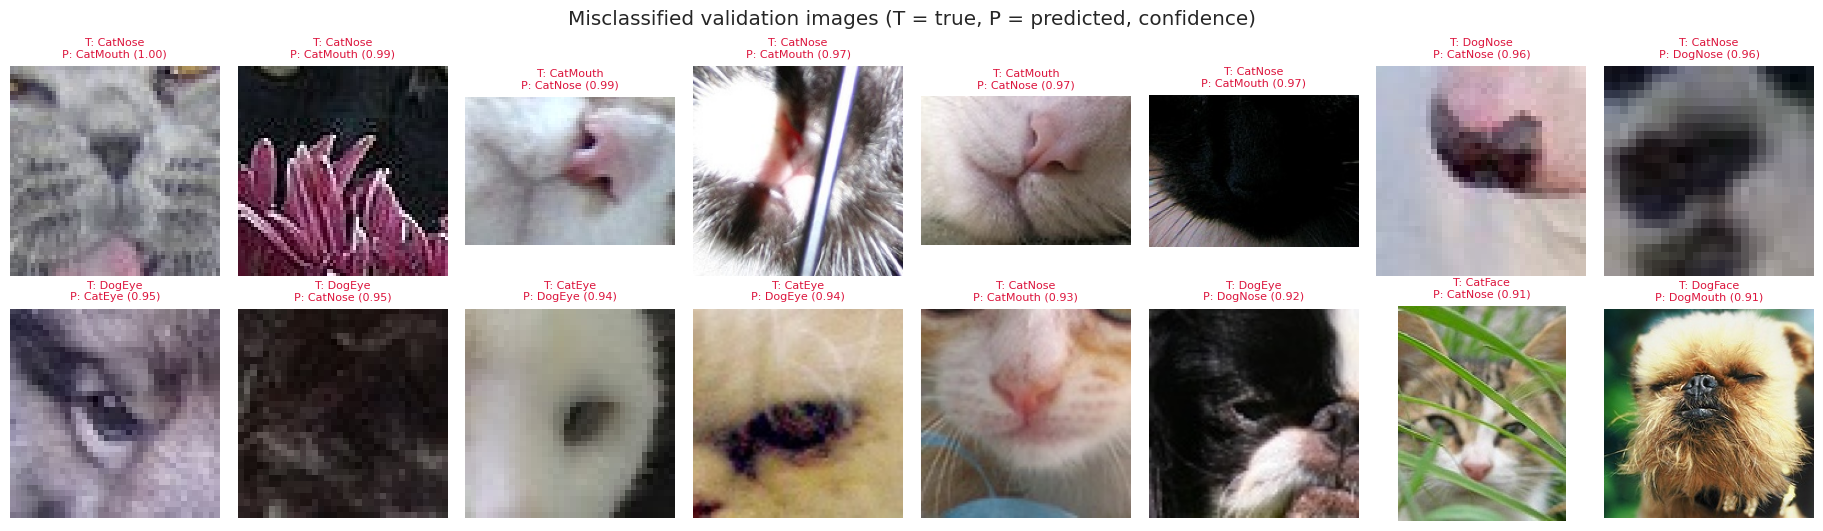

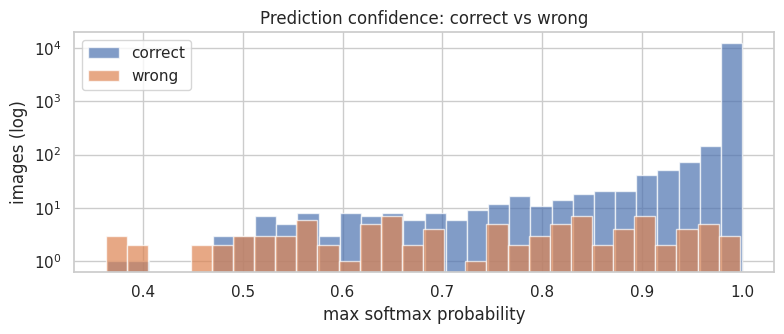

Mean confidence - correct: 0.9941, wrong: 0.7245


In [20]:
wrong = np.where(val_pred != val_y)[0]
wrong = wrong[np.argsort(-val_probs[wrong].max(1))]          # most confident mistakes first
n_show = min(16, len(wrong))
if n_show:
    cols = 8; rows = int(np.ceil(n_show / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(2.3 * cols, 2.7 * rows), squeeze=False)
    for ax in axes.flat: ax.axis("off")
    for ax, i in zip(axes.flat, wrong[:n_show]):
        ax.imshow(Image.open(va_df.path[i]).convert("RGB"))
        ax.set_title(f"T: {CLASSES[val_y[i]]}\nP: {CLASSES[val_pred[i]]} ({val_probs[i].max():.2f})", fontsize=8, color="crimson")
    plt.suptitle("Misclassified validation images (T = true, P = predicted, confidence)")
    plt.tight_layout(); plt.savefig(f"{OUT_DIR}/fig_misclassified.png", dpi=150); plt.show()
else:
    print("No misclassified validation images.")

conf = val_probs.max(1); correct = val_pred == val_y
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(conf[correct], bins=30, alpha=0.7, label="correct")
if (~correct).any(): ax.hist(conf[~correct], bins=30, alpha=0.7, label="wrong")
ax.set_yscale("log"); ax.set_xlabel("max softmax probability"); ax.set_ylabel("images (log)")
ax.set_title("Prediction confidence: correct vs wrong"); ax.legend()
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/fig_confidence.png", dpi=150); plt.show()
print(f"Mean confidence - correct: {conf[correct].mean():.4f}" +
      (f", wrong: {conf[~correct].mean():.4f}" if (~correct).any() else ""))

### 6.3 Comparison experiments
Same data split and seed, one setting changed each time, so the effect of each choice can be compared:
- **Frozen backbone:** only the head is trained (feature extraction, no fine-tuning).
- **No augmentation:** the main setup, but training images only resized and normalised.
- **Other architecture:** EfficientNet-B0 with the main setup.

Set `RUN_COMPARISONS = False` in the configuration cell to skip this section.

,experiment,best_epoch,epochs_run,val_loss,val_acc,macro_f1,minutes
0,resnet50 fine-tuned + augmentation (main),6,7,0.0231,0.9925,0.9924,36.3503


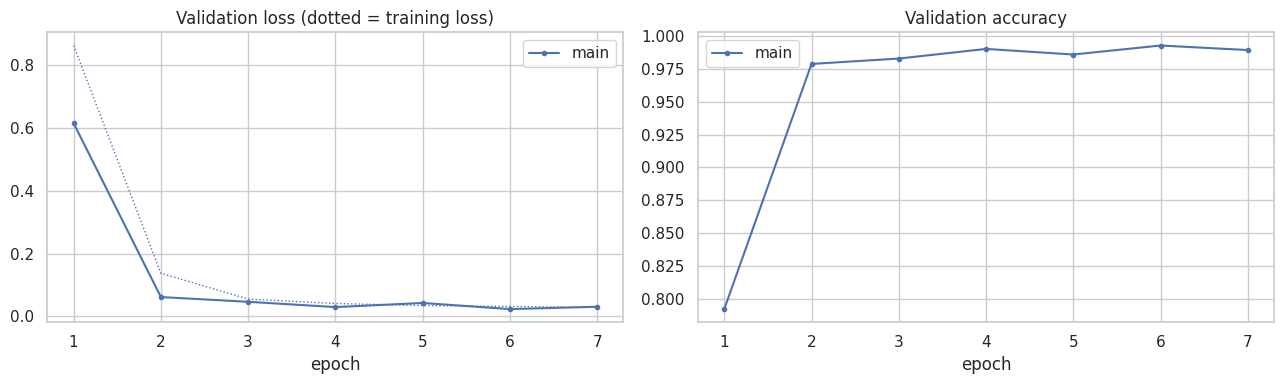

In [21]:
results = [dict(experiment=f"{ARCH} fine-tuned + augmentation (main)", best_epoch=best_epoch,
                epochs_run=len(history), val_loss=val_loss, val_acc=val_acc, macro_f1=f1,
                minutes=history.secs.sum() / 60)]
histories = {"main": history}

def evaluate(m):
    pr, yy = predict(m, val_loader)
    pd_ = pr.argmax(1)
    loss = nn.functional.nll_loss(torch.log(torch.tensor(pr) + 1e-12), torch.tensor(yy)).item()
    return loss, accuracy_score(yy, pd_), precision_recall_fscore_support(yy, pd_, average="macro")[2]

if RUN_COMPARISONS:
    noaug_loader = make_loader(tr_df, eval_tf, shuffle=True)
    experiments = [
        ("frozen", f"{ARCH} frozen backbone (head only)", dict(arch=ARCH, fine_tune=False, max_epochs=4)),
        ("noaug",  f"{ARCH} fine-tuned, no augmentation", dict(arch=ARCH, train_loader=noaug_loader)),
        ("effb0",  "efficientnet_b0 fine-tuned + augmentation", dict(arch="efficientnet_b0")),
    ]
    for key, label, kw in experiments:
        m, h, be = train_model(key, **kw)
        l, a, f = evaluate(m)
        results.append(dict(experiment=label, best_epoch=be, epochs_run=len(h), val_loss=l, val_acc=a,
                            macro_f1=f, minutes=h.secs.sum() / 60))
        histories[key] = h; h.to_csv(f"{OUT_DIR}/history_{key}.csv", index=False)
        del m; torch.cuda.empty_cache()

results_df = pd.DataFrame(results).round(4)
display(results_df); results_df.to_csv(f"{OUT_DIR}/experiment_comparison.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for key, h in histories.items():
    axes[0].plot(h.epoch, h.val_loss, "o-", label=key, ms=3)
    axes[1].plot(h.epoch, h.val_acc, "o-", label=key, ms=3)
    axes[0].plot(h.epoch, h.train_loss, ":", color=axes[0].lines[-1].get_color(), lw=1)
axes[0].set_title("Validation loss (dotted = training loss)"); axes[1].set_title("Validation accuracy")
for ax in axes: ax.set_xlabel("epoch"); ax.legend()
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/fig_experiment_comparison.png", dpi=150); plt.show()

In [22]:
   !cd /content && zip -qr outputs.zip outputs

## Reproducibility: environment and output files

In [ ]:
env = {"python": __import__("sys").version.split()[0], "torch": torch.__version__,
       "torchvision": torchvision.__version__, "numpy": np.__version__, "pandas": pd.__version__,
       "scikit-learn": __import__("sklearn").__version__, "device": str(DEVICE),
       "gpu": torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "none", "seed": SEED}
pd.Series(env).to_csv(f"{OUT_DIR}/environment.csv", header=False)
print(pd.Series(env).to_string())
print("\nOutput files:")
for f in sorted(os.listdir(OUT_DIR)):
    if not f.startswith("."):
        print("  ", f)